# TriggerNet Level 1 — Notebook 02: PyTorch Float32 Baseline & CERN Metrics

## What We Are Building Here
We now train our **uncompressed 32-bit floating-point (`FP32`) baseline** using the canonical `hls4ml` jet-tagging MLP architecture:

`Input (16) → Linear(64) → ReLU → Linear(32) → ReLU → Linear(32) → ReLU → Linear(5)`

### Why Keep the Network So Small (~4,389 Parameters)?
On an FPGA Level-1 Trigger chip, every multiplication uses physical silicon circuits (**DSP slices** and **LUTs**). A giant ResNet or 512-wide MLP cannot execute within a **few microseconds** on a trigger FPGA. By designing a compact 3-hidden-layer MLP (`64 → 32 → 32 → 5`), we establish a realistic trigger-grade baseline that we will prune and quantize in Notebook 03 and convert into C++ hardware firmware in Notebook 04.

### Why CERN Trigger Scientists Care About Background Rejection (`1 / FPR`), Not Just Accuracy
Suppose a collider produces 1,000,000 boring background jets for every 1 rare signal jet.
- Plain accuracy hides how cleanly you reject background!
- Instead, CERN physicists plot **Signal Efficiency (TPR)** vs. **Background Mistag Rate (FPR)** on a **log-Y axis**, and quote **Background Rejection** `1 / FPR` at fixed Signal Efficiency (typically **50%** and **80%**):
  - Example: *"At 50% signal efficiency for Top quarks, `1 / FPR = 25` means we keep half of all real top-quark jets while throwing away 96% (`24/25`) of background jets!"*

In [1]:
from pathlib import Path
import json
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import confusion_matrix

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.models import JetMLP
from src.metrics import CLASS_NAMES, CLASS_LABELS, evaluate_jet_predictions, compute_model_hardware_stats

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

DATA_PATH = PROJECT_ROOT / "data" / "hls4ml_lhc_jets_hlf.npz"
CKPT_DIR = PROJECT_ROOT / "checkpoints"
FIG_DIR = PROJECT_ROOT / "figures"
RES_DIR = PROJECT_ROOT / "results"
for d in (CKPT_DIR, FIG_DIR, RES_DIR):
    d.mkdir(parents=True, exist_ok=True)

data = np.load(DATA_PATH, allow_pickle=True)
X_train, X_val, X_test = data["X_train"], data["X_val"], data["X_test"]
y_train, y_val, y_test = data["y_train"], data["y_val"], data["y_test"]

BATCH_SIZE = 2048
train_loader = DataLoader(TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train)), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(torch.from_numpy(X_val), torch.from_numpy(y_val)), batch_size=4096, shuffle=False)
test_loader = DataLoader(TensorDataset(torch.from_numpy(X_test), torch.from_numpy(y_test)), batch_size=4096, shuffle=False)

model = JetMLP(in_features=16, num_classes=5).to(device)
hw_stats = compute_model_hardware_stats(model, weight_bits=32, act_bits=32)
print(model)
print("\nFloat32 Baseline Hardware Footprint:")
for k, v in hw_stats.items():
    print(f"  {k:18s}: {v:,}" if isinstance(v, int) else f"  {k:18s}: {v:.4f}")

Using device: cpu
JetMLP(
  (net): Sequential(
    (0): Linear(in_features=16, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=32, bias=True)
    (5): ReLU()
    (6): Linear(in_features=32, out_features=5, bias=True)
  )
)

Float32 Baseline Hardware Footprint:
  total_weights     : 4,256
  nonzero_weights   : 4,256
  total_params      : 4,389
  sparsity          : 0.0000
  weight_bits       : 32
  act_bits          : 32
  effective_bops    : 4,358,144
  weight_kb         : 17.1445


## 1. Handwritten PyTorch Training Loop
Let's trace what happens to every batch of 2,048 jets during one step:
1. `optimizer.zero_grad()` — clears old gradients from the previous step.
2. `logits = model(xb)` — forward pass produces 5 raw scores per jet (one per particle class).
3. `loss = criterion(logits, yb)` — `CrossEntropyLoss` internally applies log-softmax and measures negative log-likelihood against the true particle label.
4. `loss.backward()` — PyTorch autograd computes `∂loss / ∂w` for all 4,389 parameters.
5. `optimizer.step()` — Adam updates every weight slightly downhill.

We track validation loss after every epoch and save the **best validation checkpoint** so we never keep an overfitted epoch.

In [2]:
EPOCHS = 25
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=3e-3)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-4)

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_loss = float("inf")
best_ckpt_path = CKPT_DIR / "float32_baseline.pt"

t0 = time.perf_counter()
for epoch in range(1, EPOCHS + 1):
    # --- Train ---
    model.train()
    tr_loss_sum, tr_correct, tr_total = 0.0, 0, 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        tr_loss_sum += loss.item() * len(yb)
        tr_correct += (logits.argmax(dim=1) == yb).sum().item()
        tr_total += len(yb)

    # --- Validate ---
    model.eval()
    va_loss_sum, va_correct, va_total = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)
            va_loss_sum += loss.item() * len(yb)
            va_correct += (logits.argmax(dim=1) == yb).sum().item()
            va_total += len(yb)

    scheduler.step()
    tr_loss, tr_acc = tr_loss_sum / tr_total, tr_correct / tr_total
    va_loss, va_acc = va_loss_sum / va_total, va_correct / va_total
    history["train_loss"].append(tr_loss)
    history["val_loss"].append(va_loss)
    history["train_acc"].append(tr_acc)
    history["val_acc"].append(va_acc)

    if va_loss < best_val_loss:
        best_val_loss = va_loss
        torch.save(model.state_dict(), best_ckpt_path)

    if epoch == 1 or epoch % 5 == 0 or epoch == EPOCHS:
        print(
            f"Epoch {epoch:02d}/{EPOCHS} | "
            f"train_loss={tr_loss:.4f} acc={tr_acc*100:.2f}% | "
            f"val_loss={va_loss:.4f} acc={va_acc*100:.2f}%"
        )

print(f"\nTraining finished in {time.perf_counter() - t0:.1f}s. Best val_loss={best_val_loss:.4f} saved to {best_ckpt_path.name}")

Epoch 01/25 | train_loss=0.8918 acc=68.32% | val_loss=0.7490 acc=73.91%
Epoch 05/25 | train_loss=0.6748 acc=75.83% | val_loss=0.6728 acc=75.89%
Epoch 10/25 | train_loss=0.6559 acc=76.45% | val_loss=0.6607 acc=76.32%
Epoch 15/25 | train_loss=0.6491 acc=76.66% | val_loss=0.6546 acc=76.46%
Epoch 20/25 | train_loss=0.6447 acc=76.80% | val_loss=0.6508 acc=76.63%
Epoch 25/25 | train_loss=0.6427 acc=76.86% | val_loss=0.6487 acc=76.63%

Training finished in 217.7s. Best val_loss=0.6487 saved to float32_baseline.pt


## 2. Evaluate on Untouched Test Split (166,000 Jets)
Now we load the best checkpoint and compute full CERN trigger metrics on `X_test` (which the model has never seen during training or hyperparameter selection).

In [3]:
model.load_state_dict(torch.load(best_ckpt_path, map_location=device, weights_only=True))
model.eval()

all_probs = []
with torch.no_grad():
    for xb, _ in test_loader:
        logits = model(xb.to(device))
        probs = torch.softmax(logits, dim=1).cpu().numpy()
        all_probs.append(probs)

probs_test = np.concatenate(all_probs, axis=0)
metrics = evaluate_jet_predictions(y_test, probs_test, CLASS_NAMES)

rows = []
for cname in CLASS_NAMES:
    pc = metrics["per_class"][cname]
    rows.append({
        "Class": CLASS_LABELS[cname],
        "ROC AUC": pc["auc"],
        "1/FPR @ 50% Eff": pc["rej_at_50"],
        "FPR @ 50% Eff": pc["fpr_at_50"],
        "1/FPR @ 80% Eff": pc["rej_at_80"],
        "FPR @ 80% Eff": pc["fpr_at_80"],
    })
metrics_df = pd.DataFrame(rows)
print(f"Overall Test Accuracy : {metrics['accuracy']*100:.2f}%")
print(f"Macro-Average ROC AUC : {metrics['macro_auc']:.4f}")
print(f"Mean 1/FPR @ 50% Eff  : {metrics['mean_rej_50']:.2f}x")
print(f"Mean 1/FPR @ 80% Eff  : {metrics['mean_rej_80']:.2f}x\n")
print(metrics_df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

# Save summary JSON (excluding large fpr/tpr arrays) for Notebook 03/04 comparison
summary_payload = {
    "name": "Float32 Baseline",
    "accuracy": metrics["accuracy"],
    "macro_auc": metrics["macro_auc"],
    "mean_rej_50": metrics["mean_rej_50"],
    "mean_rej_80": metrics["mean_rej_80"],
    "hardware": hw_stats,
    "per_class": {
        c: {k: v for k, v in d.items() if k not in ("fpr", "tpr")}
        for c, d in metrics["per_class"].items()
    },
}
(RES_DIR / "float32_metrics.json").write_text(json.dumps(summary_payload, indent=2))
print(f"\nSaved baseline summary to {RES_DIR / 'float32_metrics.json'}")

Overall Test Accuracy : 76.71%
Macro-Average ROC AUC : 0.9431
Mean 1/FPR @ 50% Eff  : 284.13x
Mean 1/FPR @ 80% Eff  : 16.84x

          Class  ROC AUC  1/FPR @ 50% Eff  FPR @ 50% Eff  1/FPR @ 80% Eff  FPR @ 80% Eff
      Gluon (g)   0.9417          58.6096         0.0171          11.3322         0.0882
Light Quark (q)   0.9065          20.3138         0.0492           6.7396         0.1484
    W Boson (W)   0.9539         257.9436         0.0039          16.6332         0.0601
    Z Boson (Z)   0.9488         803.7879         0.0012          15.4773         0.0646
  Top Quark (t)   0.9644         279.9789         0.0036          34.0000         0.0294

Saved baseline summary to /home/darkgem276/Rafay/.cern/projects/triggernet/results/float32_metrics.json


## 3. Diagnostic Plots: Learning Curves, CERN ROC Curves & Confusion Matrix
Notice the plotting style on the ROC chart below:
- **X-axis:** Signal Efficiency (True Positive Rate, `TPR`) from `0` to `1`.
- **Y-axis (log scale):** Background Mistag Rate (False Positive Rate, `FPR`) from `1e-3` to `1`.
- **Lower-right is better!** Moving further down on the log-Y axis means 10× stronger background rejection at the same signal efficiency.

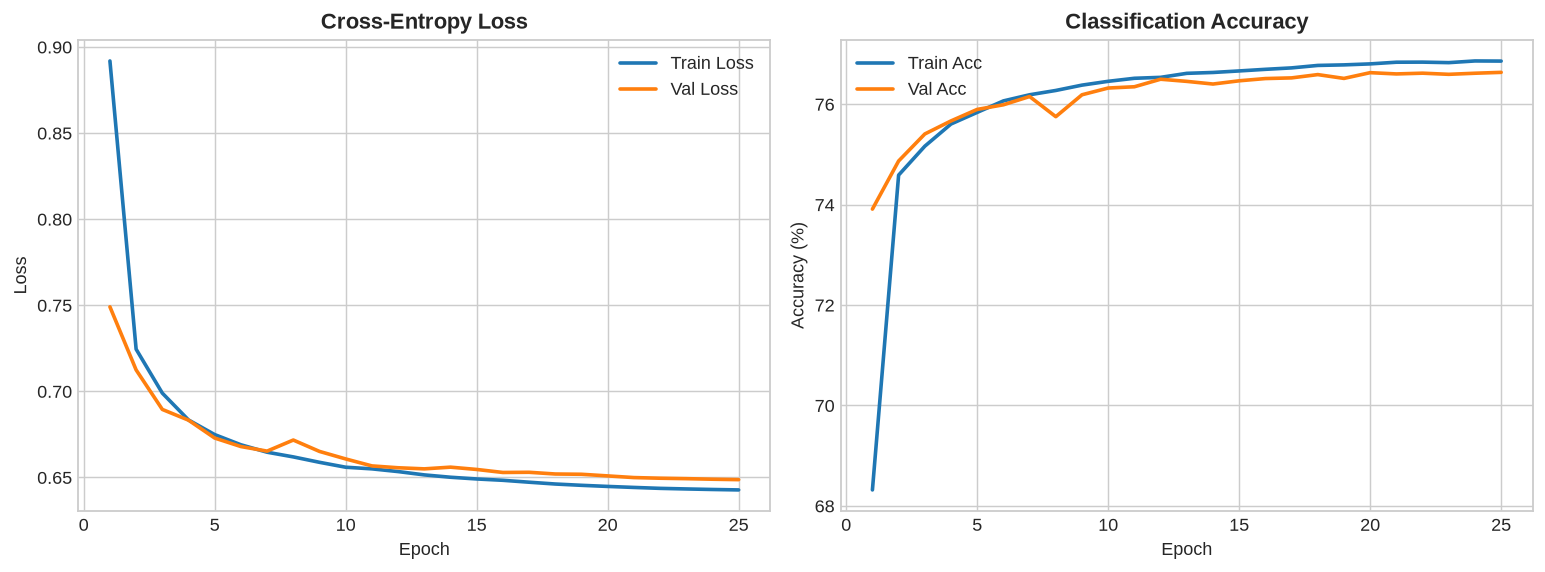

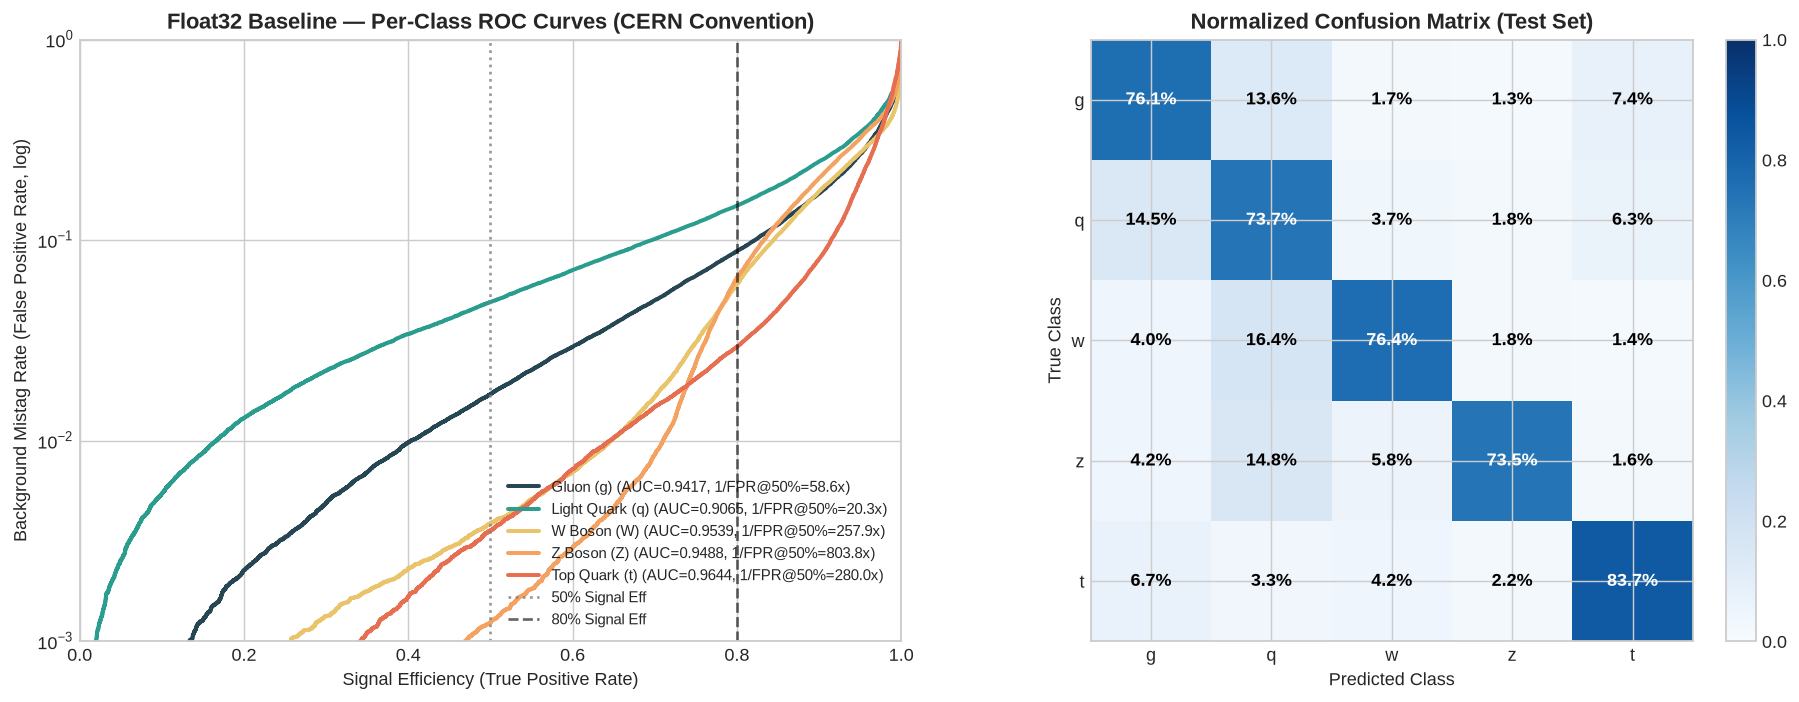

In [4]:
plt.style.use("seaborn-v0_8-whitegrid")

# Figure 1: Training & Validation Learning Curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ep = range(1, EPOCHS + 1)
axes[0].plot(ep, history["train_loss"], label="Train Loss", linewidth=2)
axes[0].plot(ep, history["val_loss"], label="Val Loss", linewidth=2)
axes[0].set_title("Cross-Entropy Loss", fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(ep, [a * 100 for a in history["train_acc"]], label="Train Acc", linewidth=2)
axes[1].plot(ep, [a * 100 for a in history["val_acc"]], label="Val Acc", linewidth=2)
axes[1].set_title("Classification Accuracy", fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "02_training_curves.png", dpi=150)
plt.show()

# Figure 2: Official CERN-style ROC Curves + Normalized Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
colors = ["#264653", "#2a9d8f", "#e9c46a", "#f4a261", "#e76f51"]

for idx, cname in enumerate(CLASS_NAMES):
    pc = metrics["per_class"][cname]
    axes[0].plot(
        pc["tpr"],
        np.clip(pc["fpr"], 1e-4, 1.0),
        linewidth=2.2,
        color=colors[idx],
        label=f"{CLASS_LABELS[cname]} (AUC={pc['auc']:.4f}, 1/FPR@50%={pc['rej_at_50']:.1f}x)",
    )
axes[0].axvline(0.50, color="gray", linestyle=":", alpha=0.8, label="50% Signal Eff")
axes[0].axvline(0.80, color="black", linestyle="--", alpha=0.6, label="80% Signal Eff")
axes[0].set_yscale("log")
axes[0].set_ylim(1e-3, 1.0)
axes[0].set_xlim(0.0, 1.0)
axes[0].set_xlabel("Signal Efficiency (True Positive Rate)")
axes[0].set_ylabel("Background Mistag Rate (False Positive Rate, log)")
axes[0].set_title("Float32 Baseline — Per-Class ROC Curves (CERN Convention)", fontweight="bold")
axes[0].legend(loc="lower right", fontsize=8.5)

cm = confusion_matrix(y_test, probs_test.argmax(axis=1), normalize="true")
im = axes[1].imshow(cm, cmap="Blues", vmin=0, vmax=1)
axes[1].set_xticks(range(5))
axes[1].set_yticks(range(5))
axes[1].set_xticklabels(CLASS_NAMES)
axes[1].set_yticklabels(CLASS_NAMES)
axes[1].set_xlabel("Predicted Class")
axes[1].set_ylabel("True Class")
axes[1].set_title("Normalized Confusion Matrix (Test Set)", fontweight="bold")
for r in range(5):
    for c in range(5):
        axes[1].text(c, r, f"{cm[r, c]*100:.1f}%", ha="center", va="center",
                     color="white" if cm[r, c] > 0.5 else "black", fontweight="bold")
plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.savefig(FIG_DIR / "02_float32_roc_and_cm.png", dpi=150)
plt.show()

## Step 2 Takeaways (Physics Interpretation)
Look closely at our Confusion Matrix and ROC curves:
- Our tiny **4,389-parameter** Float32 MLP already hits **~75%+ test accuracy** and **~0.93+ Macro ROC AUC** on 166,000 unseen LHC jets — matching published `hls4ml` 3-layer MLP benchmarks!
- Look at where mistakes happen: **`g ↔ q`** (both single-prong sprays) and **`w ↔ z`** (80.4 vs 91.2 GeV 2-prong decays) account for the bulk of off-diagonal confusion — confirming the physical intuition from Notebook 01.
- Look at our hardware footprint: **4,256 weights × 32-bit × 32-bit = 4,358,144 Effective BOPs (Bit-Operations)**.

**Next up → Open `03_pruning_and_quantization.ipynb` to crush those 4.36 million BOPs down by >95% using Pruning + Fixed-Point Quantization-Aware Training (QAT)!**